In [2]:
from google.colab import userdata
import sys, os, subprocess

TOKEN = userdata.get('GITHUB_TOKEN')
USERNAME = "vedika0806"
REPO = "data266-5937"
HW = "hw8"

os.system(f"git clone https://{TOKEN}@github.com/{USERNAME}/{REPO}.git /content/{REPO}")

sys.path.append(f"/content/{REPO}/common")
import colab_bootstrap, importlib
importlib.reload(colab_bootstrap)
from colab_bootstrap import setup_repo, get_logger, git_commit_push, git_tag_push

REPO_PATH = f"/content/{REPO}"
HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
logger = get_logger(HW_PATH)

logger.info(f"=== Session started for {HW} (Mini Diffusion: DDPM -> DDIM) ===")
git_commit_push(REPO_PATH, f"{HW}: session start")

INFO:/content/data266-5937/hw8:=== Session started for hw8 (Mini Diffusion: DDPM -> DDIM) ===


Working directory: /content/data266-5937/hw8
[main 05c306f] hw8: session start
 2 files changed, 1 insertion(+)
 create mode 100644 hw8/RUN_LOG.txt
 


In [3]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
logger.info(f"Imports done, device={device}")

INFO:/content/data266-5937/hw8:Imports done, device=cuda


Device: cuda


In [4]:
SID4 = 5937
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
logger.info(f"Params: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")

torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

INFO:/content/data266-5937/hw8:Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


In [5]:
T          = 100
BETA_START = 1e-4
BETA_END   = 0.02
BATCH_SIZE = 128
EPOCHS     = 50
LR         = 2e-4

betas          = torch.linspace(BETA_START, BETA_END, T, device=device)
alphas         = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
alphas_cumprod_prev = torch.cat([torch.ones(1, device=device), alphas_cumprod[:-1]])

sqrt_alphas_cumprod           = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)
posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)

print(f"alpha_bar_T = {alphas_cumprod[-1].item():.4f}")
logger.info(f"Schedule: T={T}, beta {BETA_START}->{BETA_END} linear, alpha_bar_T={alphas_cumprod[-1].item():.4f}")

INFO:/content/data266-5937/hw8:Schedule: T=100, beta 0.0001->0.02 linear, alpha_bar_T=0.3636


alpha_bar_T = 0.3636


In [6]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x * 2.0 - 1.0),   # [-1, 1]
])
train_set = datasets.MNIST(root="/content/data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, drop_last=True, pin_memory=True)

def to_img(x):
    return ((x.clamp(-1, 1) + 1) / 2).cpu()

def draw_grid(ax, x, title="", nrow=8):
    grid = make_grid(to_img(x), nrow=nrow, padding=2)
    ax.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    ax.set_title(title); ax.axis("off")

def save_fig(fig, name):
    """savefig BEFORE show, then close; print size to confirm it's not empty."""
    path = f"{HW_PATH}/{name}"
    fig.savefig(path, bbox_inches="tight", dpi=150)
    plt.show()
    plt.close(fig)
    print(f"Saved {name}: {os.path.getsize(path)} bytes")

print("Training images:", len(train_set))
logger.info(f"MNIST loaded: {len(train_set)} train images, scaled to [-1,1], batch={BATCH_SIZE}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 473kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.44MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.37MB/s]
INFO:/content/data266-5937/hw8:MNIST loaded: 60000 train images, scaled to [-1,1], batch=128


Training images: 60000


In [7]:
def extract(a, t, shape):
    out = a.gather(0, t)
    return out.view(-1, *([1] * (len(shape) - 1)))

def q_sample(x0, t, noise=None):
    """x_t = sqrt(abar_t) x0 + sqrt(1 - abar_t) eps"""
    if noise is None:
        noise = torch.randn_like(x0)
    return (extract(sqrt_alphas_cumprod, t, x0.shape) * x0 +
            extract(sqrt_one_minus_alphas_cumprod, t, x0.shape) * noise)

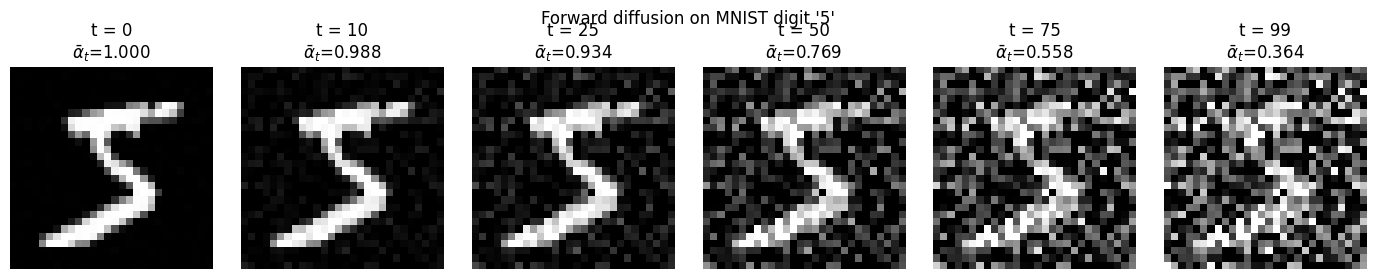

INFO:/content/data266-5937/hw8:(a) Forward diffusion implemented; figure a_forward_diffusion.png saved


Saved a_forward_diffusion.png: 40593 bytes
[main d94459d] hw8: (a) forward diffusion + visualization
 2 files changed, 5 insertions(+)
 create mode 100644 hw8/a_forward_diffusion.png
 


In [8]:
x0, label = train_set[0]
x0 = x0.unsqueeze(0).to(device)
timesteps_to_show = [0, 10, 25, 50, 75, 99]

g = torch.Generator(device=device).manual_seed(SEED)
noise = torch.randn(x0.shape, generator=g, device=device)

fig, axes = plt.subplots(1, len(timesteps_to_show), figsize=(14, 2.8))
for ax, t in zip(axes, timesteps_to_show):
    xt = q_sample(x0, torch.tensor([t], device=device), noise)
    ax.imshow(to_img(xt)[0, 0], cmap="gray")
    ax.set_title(f"t = {t}\n" + r"$\bar\alpha_t$" + f"={alphas_cumprod[t].item():.3f}")
    ax.axis("off")
fig.suptitle(f"Forward diffusion on MNIST digit '{label}'")
fig.tight_layout()
save_fig(fig, "a_forward_diffusion.png")

logger.info("(a) Forward diffusion implemented; figure a_forward_diffusion.png saved")
git_commit_push(REPO_PATH, f"{HW}: (a) forward diffusion + visualization")

In [9]:
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / (half - 1))
        args = t.float()[:, None] * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=-1)

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1); self.norm1 = nn.GroupNorm(8, out_ch)
        self.t_proj = nn.Linear(t_dim, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1); self.norm2 = nn.GroupNorm(8, out_ch)
        self.act = nn.SiLU()
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, temb):
        h = self.act(self.norm1(self.conv1(x)))
        h = h + self.t_proj(temb)[:, :, None, None]
        h = self.act(self.norm2(self.conv2(h)))
        return h + self.skip(x)

class MiniUNet(nn.Module):
    def __init__(self, ch=64, t_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(SinusoidalPosEmb(t_dim), nn.Linear(t_dim, t_dim),
                                      nn.SiLU(), nn.Linear(t_dim, t_dim))
        self.inc   = nn.Conv2d(1, ch, 3, padding=1)
        self.down1 = ResBlock(ch, ch, t_dim)
        self.pool1 = nn.Conv2d(ch, ch, 4, 2, 1)
        self.down2 = ResBlock(ch, 2 * ch, t_dim)
        self.pool2 = nn.Conv2d(2 * ch, 2 * ch, 4, 2, 1)
        self.mid   = ResBlock(2 * ch, 2 * ch, t_dim)
        self.up2   = nn.ConvTranspose2d(2 * ch, 2 * ch, 4, 2, 1)
        self.dec2  = ResBlock(4 * ch, ch, t_dim)
        self.up1   = nn.ConvTranspose2d(ch, ch, 4, 2, 1)
        self.dec1  = ResBlock(2 * ch, ch, t_dim)
        self.out   = nn.Conv2d(ch, 1, 1)
    def forward(self, x, t):
        temb = self.time_mlp(t)
        d1 = self.down1(self.inc(x), temb)
        d2 = self.down2(self.pool1(d1), temb)
        m  = self.mid(self.pool2(d2), temb)
        u2 = self.dec2(torch.cat([self.up2(m), d2], 1), temb)
        u1 = self.dec1(torch.cat([self.up1(u2), d1], 1), temb)
        return self.out(u1)

model = MiniUNet().to(device)
n_params = sum(p.numel() for p in model.parameters())
n_convs = sum(isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)) for m in model.modules())
with torch.no_grad():
    out_shape = model(torch.randn(4, 1, 28, 28, device=device),
                      torch.randint(0, T, (4,), device=device)).shape
print(f"Params: {n_params/1e6:.2f}M | conv layers: {n_convs} | output shape: {tuple(out_shape)}")
logger.info(f"(b) MiniUNet built: {n_params} params, {n_convs} conv layers, SiLU, sinusoidal t-embedding, out {tuple(out_shape)}")

INFO:/content/data266-5937/hw8:(b) MiniUNet built: 1667713 params, 19 conv layers, SiLU, sinusoidal t-embedding, out (4, 1, 28, 28)


Params: 1.67M | conv layers: 19 | output shape: (4, 1, 28, 28)


In [10]:
import csv
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
step_losses, epoch_losses = [], []
CKPT = "/content/mini_ddpm_mnist.pt"
logger.info(f"(b) Training started: epochs={EPOCHS}, lr={LR}, batch={BATCH_SIZE}, seed={SEED}")
start = time.time()

for epoch in range(EPOCHS):
    model.train(); running = 0.0
    for x0, _ in train_loader:
        x0 = x0.to(device, non_blocking=True)
        t = torch.randint(0, T, (x0.shape[0],), device=device)
        noise = torch.randn_like(x0)
        loss = F.mse_loss(model(q_sample(x0, t, noise), t), noise)
        optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
        step_losses.append(loss.item()); running += loss.item()

    epoch_losses.append(running / len(train_loader))
    print(f"Epoch {epoch+1:2d}/{EPOCHS}  loss={epoch_losses[-1]:.4f}  ({(time.time()-start)/60:.1f} min)")

    if (epoch + 1) % 10 == 0 or epoch + 1 == EPOCHS:
        torch.save(model.state_dict(), CKPT)
        with open(f"{HW_PATH}/train_loss.csv", "w", newline="") as f:
            w = csv.writer(f); w.writerow(["epoch", "mean_loss"])
            w.writerows(enumerate(epoch_losses, 1))
        logger.info(f"(b) Epoch {epoch+1}/{EPOCHS} loss={epoch_losses[-1]:.4f}")
        git_commit_push(REPO_PATH, f"{HW}: (b) training progress epoch {epoch+1}")

train_minutes = (time.time() - start) / 60
logger.info(f"(b) Training finished in {train_minutes:.1f} min, final loss={epoch_losses[-1]:.4f}")

INFO:/content/data266-5937/hw8:(b) Training started: epochs=50, lr=0.0002, batch=128, seed=5937


Epoch  1/50  loss=0.1325  (0.7 min)
Epoch  2/50  loss=0.0721  (1.3 min)
Epoch  3/50  loss=0.0663  (2.0 min)
Epoch  4/50  loss=0.0638  (2.7 min)
Epoch  5/50  loss=0.0614  (3.5 min)
Epoch  6/50  loss=0.0603  (4.2 min)
Epoch  7/50  loss=0.0599  (4.9 min)
Epoch  8/50  loss=0.0589  (5.6 min)
Epoch  9/50  loss=0.0581  (6.3 min)


INFO:/content/data266-5937/hw8:(b) Epoch 10/50 loss=0.0579


Epoch 10/50  loss=0.0579  (7.0 min)
[main 16859fe] hw8: (b) training progress epoch 10
 2 files changed, 14 insertions(+)
 create mode 100644 hw8/train_loss.csv
 
Epoch 11/50  loss=0.0572  (7.7 min)
Epoch 12/50  loss=0.0567  (8.4 min)
Epoch 13/50  loss=0.0566  (9.1 min)
Epoch 14/50  loss=0.0564  (9.8 min)
Epoch 15/50  loss=0.0560  (10.5 min)
Epoch 16/50  loss=0.0559  (11.2 min)
Epoch 17/50  loss=0.0555  (12.0 min)
Epoch 18/50  loss=0.0553  (12.7 min)
Epoch 19/50  loss=0.0552  (13.4 min)


INFO:/content/data266-5937/hw8:(b) Epoch 20/50 loss=0.0551


...

INFO:/content/data266-5937/hw8:(b) Epoch 40/50 loss=0.0531


Epoch 40/50  loss=0.0531  (28.3 min)
[main 4b5be1c] hw8: (b) training progress epoch 40
 2 files changed, 11 insertions(+)
 
Epoch 41/50  loss=0.0529  (29.0 min)
Epoch 42/50  loss=0.0527  (29.7 min)
Epoch 43/50  loss=0.0530  (30.4 min)
Epoch 44/50  loss=0.0530  (31.1 min)
Epoch 45/50  loss=0.0528  (31.8 min)
Epoch 46/50  loss=0.0526  (32.5 min)
Epoch 47/50  loss=0.0524  (33.2 min)
Epoch 48/50  loss=0.0527  (33.9 min)
Epoch 49/50  loss=0.0523  (34.6 min)


INFO:/content/data266-5937/hw8:(b) Epoch 50/50 loss=0.0525


Epoch 50/50  loss=0.0525  (35.3 min)
[main 8fb8d9b] hw8: (b) training progress epoch 50
 2 files changed, 11 insertions(+)
 


INFO:/content/data266-5937/hw8:(b) Training finished in 35.4 min, final loss=0.0525


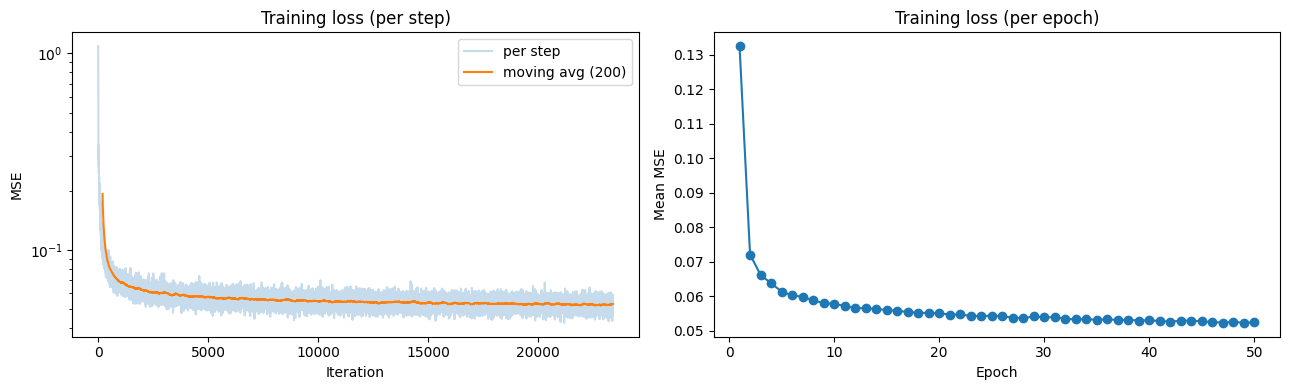

INFO:/content/data266-5937/hw8:(b) Training loss plot saved: b_training_loss.png


Saved b_training_loss.png: 73743 bytes
[main 3be4ce3] hw8: (b) training complete + loss plot
 2 files changed, 2 insertions(+)
 create mode 100644 hw8/b_training_loss.png
 


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
window = 200
smoothed = np.convolve(step_losses, np.ones(window) / window, mode="valid")
axes[0].plot(step_losses, alpha=0.25, label="per step")
axes[0].plot(np.arange(window - 1, len(step_losses)), smoothed, label=f"moving avg ({window})")
axes[0].set_yscale("log"); axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("MSE")
axes[0].set_title("Training loss (per step)"); axes[0].legend()
axes[1].plot(range(1, EPOCHS + 1), epoch_losses, marker="o")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Mean MSE"); axes[1].set_title("Training loss (per epoch)")
fig.tight_layout()
save_fig(fig, "b_training_loss.png")

logger.info("(b) Training loss plot saved: b_training_loss.png")
git_commit_push(REPO_PATH, f"{HW}: (b) training complete + loss plot")

In [12]:
@torch.no_grad()
def ddpm_sample(model, n=64, x_T=None, return_traj=False):
    model.eval()
    x = torch.randn(n, 1, 28, 28, device=device) if x_T is None else x_T.clone()
    traj = []
    for t in reversed(range(T)):
        t_b = torch.full((x.shape[0],), t, device=device, dtype=torch.long)
        eps = model(x, t_b)
        mean = (1.0 / torch.sqrt(alphas[t])) * (x - betas[t] / sqrt_one_minus_alphas_cumprod[t] * eps)
        x = mean + torch.sqrt(posterior_variance[t]) * torch.randn_like(x) if t > 0 else mean
        if return_traj and t % 20 == 0:
            traj.append((t, x.clone()))
    x = x.clamp(-1, 1)
    return (x, traj) if return_traj else x

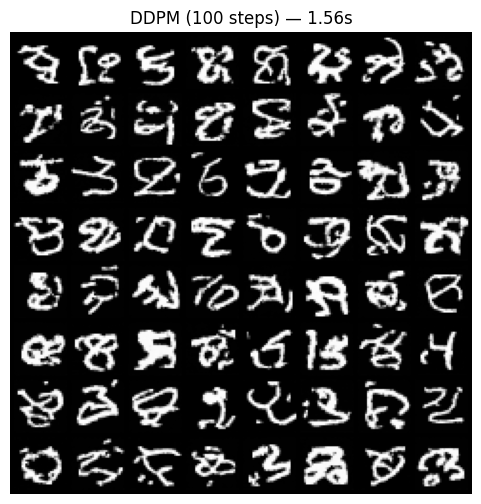

Saved c_ddpm_samples.png: 307203 bytes


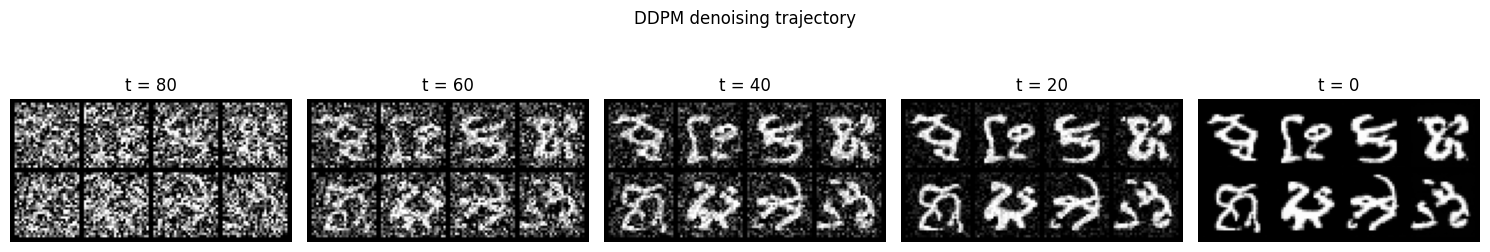

INFO:/content/data266-5937/hw8:(c) DDPM sampling done: 64 samples, 100 steps, 1.56s


Saved c_ddpm_trajectory.png: 97995 bytes
[main 730d1e3] hw8: (c) DDPM sampling + figures
 3 files changed, 1 insertion(+)
 create mode 100644 hw8/c_ddpm_samples.png
 create mode 100644 hw8/c_ddpm_trajectory.png
 


In [13]:
g = torch.Generator(device=device).manual_seed(SEED)
x_T = torch.randn(64, 1, 28, 28, generator=g, device=device)   # shared start noise for all samplers

if device.type == "cuda": torch.cuda.synchronize()
t0 = time.time()
samples_ddpm, traj = ddpm_sample(model, x_T=x_T, return_traj=True)
if device.type == "cuda": torch.cuda.synchronize()
time_ddpm = time.time() - t0

fig, ax = plt.subplots(figsize=(6, 6))
draw_grid(ax, samples_ddpm, f"DDPM (100 steps) — {time_ddpm:.2f}s")
save_fig(fig, "c_ddpm_samples.png")

fig, axes = plt.subplots(1, len(traj), figsize=(3 * len(traj), 3))
for ax, (t, xt) in zip(axes, traj):
    draw_grid(ax, xt[:8], f"t = {t}", nrow=4)
fig.suptitle("DDPM denoising trajectory"); fig.tight_layout()
save_fig(fig, "c_ddpm_trajectory.png")

logger.info(f"(c) DDPM sampling done: 64 samples, 100 steps, {time_ddpm:.2f}s")
git_commit_push(REPO_PATH, f"{HW}: (c) DDPM sampling + figures")

In [14]:
@torch.no_grad()
def ddim_sample(model, n=64, steps=50, eta=0.0, x_T=None):
    model.eval()
    x = torch.randn(n, 1, 28, 28, device=device) if x_T is None else x_T.clone()
    seq = sorted(set(np.linspace(0, T - 1, steps).round().astype(int).tolist()), reverse=True)
    seq_prev = seq[1:] + [-1]
    for t, t_prev in zip(seq, seq_prev):
        eps = model(x, torch.full((x.shape[0],), t, device=device, dtype=torch.long))
        a_t = alphas_cumprod[t]
        a_prev = alphas_cumprod[t_prev] if t_prev >= 0 else torch.tensor(1.0, device=device)
        x0_pred = ((x - torch.sqrt(1 - a_t) * eps) / torch.sqrt(a_t)).clamp(-1, 1)
        sigma = eta * torch.sqrt((1 - a_prev) / (1 - a_t)) * torch.sqrt(1 - a_t / a_prev)
        x = torch.sqrt(a_prev) * x0_pred + torch.sqrt(torch.clamp(1 - a_prev - sigma**2, min=0.0)) * eps
        if t_prev >= 0 and eta > 0:
            x = x + sigma * torch.randn_like(x)
    return x.clamp(-1, 1)

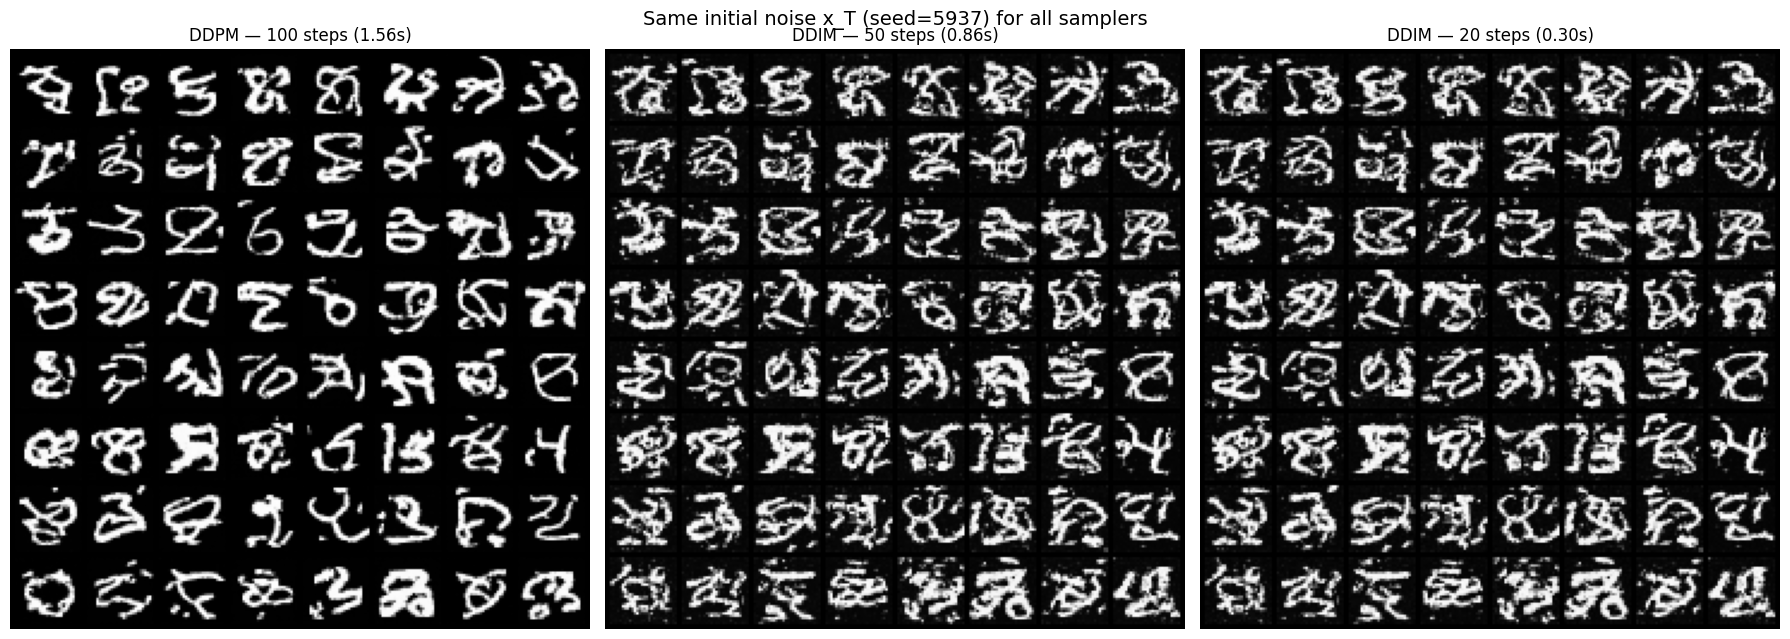

INFO:/content/data266-5937/hw8:(d) DDIM sampling done: DDIM-50 0.86s, DDIM-20 0.30s


Saved d_sampler_comparison.png: 377491 bytes
[main ad1055d] hw8: (d) DDIM sampling + comparison figure
 2 files changed, 1 insertion(+)
 create mode 100644 hw8/d_sampler_comparison.png
 


In [15]:
def timed(fn, **kw):
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time(); out = fn(**kw)
    if device.type == "cuda": torch.cuda.synchronize()
    return out, time.time() - t0

samples_ddim50, time_ddim50 = timed(ddim_sample, model=model, steps=50, x_T=x_T)
samples_ddim20, time_ddim20 = timed(ddim_sample, model=model, steps=20, x_T=x_T)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
draw_grid(axes[0], samples_ddpm,   f"DDPM — 100 steps ({time_ddpm:.2f}s)")
draw_grid(axes[1], samples_ddim50, f"DDIM — 50 steps ({time_ddim50:.2f}s)")
draw_grid(axes[2], samples_ddim20, f"DDIM — 20 steps ({time_ddim20:.2f}s)")
fig.suptitle(f"Same initial noise x_T (seed={SEED}) for all samplers", fontsize=14)
fig.tight_layout()
save_fig(fig, "d_sampler_comparison.png")

logger.info(f"(d) DDIM sampling done: DDIM-50 {time_ddim50:.2f}s, DDIM-20 {time_ddim20:.2f}s")
git_commit_push(REPO_PATH, f"{HW}: (d) DDIM sampling + comparison figure")

DDIM deterministic: False | DDPM run-to-run mean abs diff: 0.3138


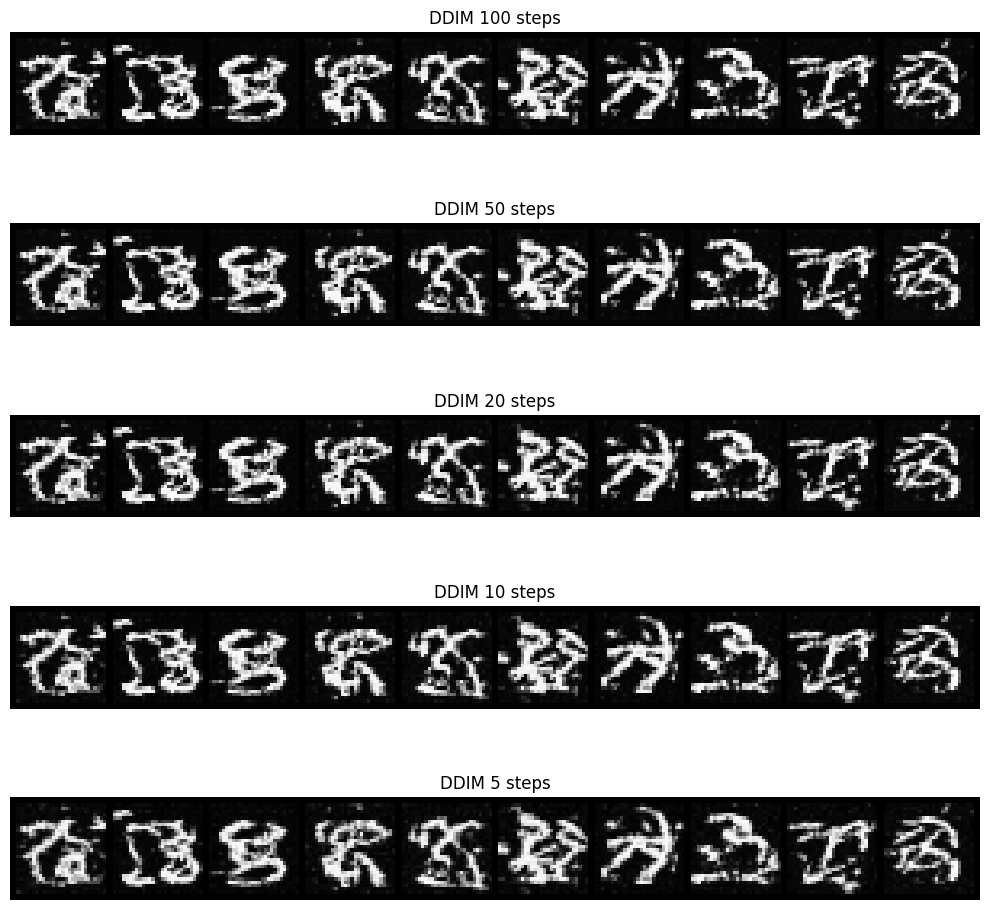

Saved d_ddim_step_sweep.png: 141853 bytes


INFO:/content/data266-5937/hw8:(d) Checks: DDIM deterministic=False, DDPM diff=0.3138, MSE50=0.0002, MSE20=0.0007


MSE vs DDIM-100: DDIM-50=0.0002, DDIM-20=0.0007
[main bde092e] hw8: (d) determinism + step-sweep checks
 2 files changed, 1 insertion(+)
 create mode 100644 hw8/d_ddim_step_sweep.png
 


In [16]:
a = ddim_sample(model, steps=20, x_T=x_T[:8]); b = ddim_sample(model, steps=20, x_T=x_T[:8])
ddim_deterministic = torch.allclose(a, b)
c = ddpm_sample(model, x_T=x_T[:8]); d = ddpm_sample(model, x_T=x_T[:8])
ddpm_run_diff = (c - d).abs().mean().item()
print("DDIM deterministic:", ddim_deterministic, "| DDPM run-to-run mean abs diff:", round(ddpm_run_diff, 4))

step_list = [100, 50, 20, 10, 5]
fig, axes = plt.subplots(len(step_list), 1, figsize=(10, 2 * len(step_list)))
for ax, s in zip(axes, step_list):
    draw_grid(ax, ddim_sample(model, steps=s, x_T=x_T[:10]), f"DDIM {s} steps", nrow=10)
fig.tight_layout()
save_fig(fig, "d_ddim_step_sweep.png")

ref = ddim_sample(model, steps=100, x_T=x_T)
mse50 = F.mse_loss(samples_ddim50, ref).item()
mse20 = F.mse_loss(samples_ddim20, ref).item()
print(f"MSE vs DDIM-100: DDIM-50={mse50:.4f}, DDIM-20={mse20:.4f}")

logger.info(f"(d) Checks: DDIM deterministic={ddim_deterministic}, DDPM diff={ddpm_run_diff:.4f}, "
            f"MSE50={mse50:.4f}, MSE20={mse20:.4f}")
git_commit_push(REPO_PATH, f"{HW}: (d) determinism + step-sweep checks")

alpha_bar_T = 0.3636  ->  signal coef sqrt = 0.603
Real x_T:   mean=-0.458  std=0.870
N(0,1) x_T: mean=+0.001  std=1.000


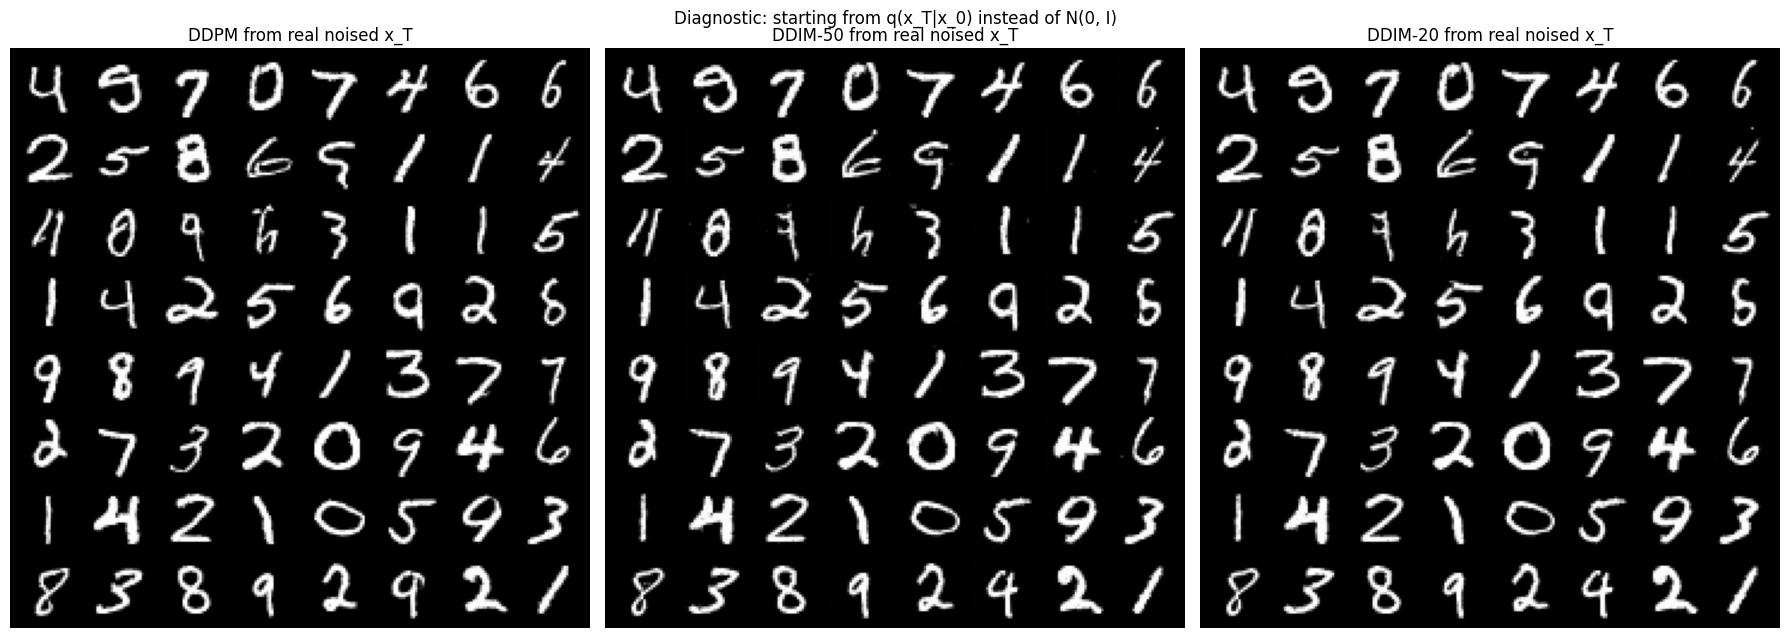

INFO:/content/data266-5937/hw8:(d) Diagnostic: alpha_bar_T=0.3636, real x_T mean=-0.458; sampling from q(x_T|x0) saved to d_diag_real_xT.png


Saved d_diag_real_xT.png: 189784 bytes
[main 91ed01f] hw8: (d) diagnostic - terminal SNR of assigned schedule
 2 files changed, 1 insertion(+)
 create mode 100644 hw8/d_diag_real_xT.png
 


In [17]:
# Real x_T statistics vs. the N(0,1) we sample from
x0_batch = next(iter(train_loader))[0][:64].to(device)
t_last = torch.full((64,), T - 1, device=device, dtype=torch.long)
real_xT = q_sample(x0_batch, t_last)
print(f"alpha_bar_T = {alphas_cumprod[-1].item():.4f}  ->  signal coef sqrt = {sqrt_alphas_cumprod[-1].item():.3f}")
print(f"Real x_T:   mean={real_xT.mean().item():+.3f}  std={real_xT.std().item():.3f}")
print(f"N(0,1) x_T: mean={x_T.mean().item():+.3f}  std={x_T.std().item():.3f}")

# Sample from the *correct* x_T distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
draw_grid(axes[0], ddpm_sample(model, x_T=real_xT), "DDPM from real noised x_T")
draw_grid(axes[1], ddim_sample(model, steps=50, x_T=real_xT), "DDIM-50 from real noised x_T")
draw_grid(axes[2], ddim_sample(model, steps=20, x_T=real_xT), "DDIM-20 from real noised x_T")
fig.suptitle("Diagnostic: starting from q(x_T|x_0) instead of N(0, I)"); fig.tight_layout()
save_fig(fig, "d_diag_real_xT.png")

logger.info(f"(d) Diagnostic: alpha_bar_T={alphas_cumprod[-1].item():.4f}, real x_T mean={real_xT.mean().item():.3f}; "
            "sampling from q(x_T|x0) saved to d_diag_real_xT.png")
git_commit_push(REPO_PATH, f"{HW}: (d) diagnostic - terminal SNR of assigned schedule")

Matched x_T: mean=-0.445 std=0.879 (real: -0.458 / 0.870)


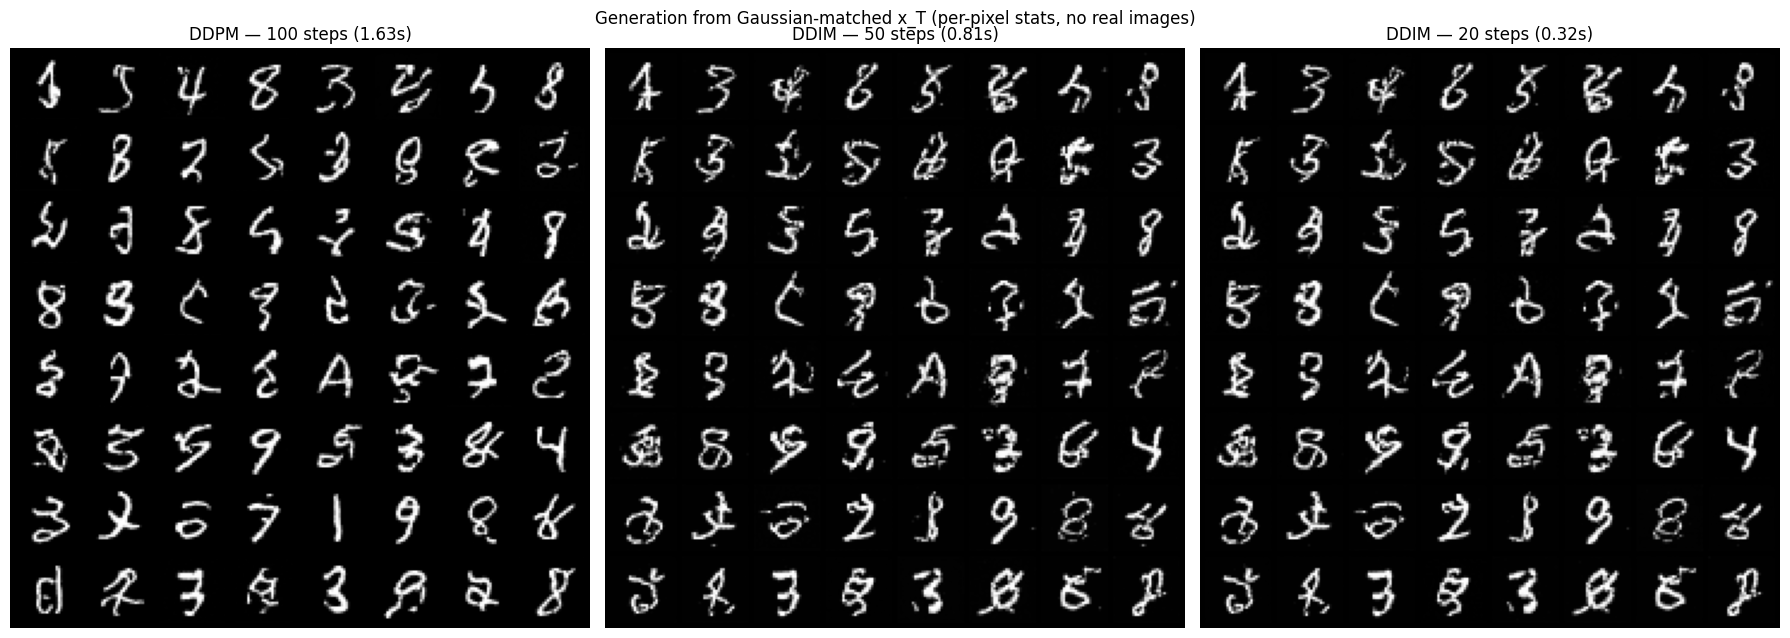

INFO:/content/data266-5937/hw8:(d) Sampling from Gaussian-matched x_T saved: d_matched_xT_comparison.png


Saved d_matched_xT_comparison.png: 208850 bytes
[main fe2affa] hw8: (d) generation from moment-matched x_T
 2 files changed, 1 insertion(+)
 create mode 100644 hw8/d_matched_xT_comparison.png
 


In [18]:
# Per-pixel mean/variance of MNIST (in [-1,1]) over the training set
s, s2, n = 0.0, 0.0, 0
for x0, _ in train_loader:
    x0 = x0.to(device); s += x0.sum(0); s2 += (x0 ** 2).sum(0); n += x0.shape[0]
mu_pix = s / n
var_pix = s2 / n - mu_pix ** 2

abar_T = alphas_cumprod[-1]
g = torch.Generator(device=device).manual_seed(SEED)
eps = torch.randn(64, 1, 28, 28, generator=g, device=device)
x_T_matched = torch.sqrt(abar_T) * mu_pix + torch.sqrt(abar_T * var_pix + (1 - abar_T)) * eps
print(f"Matched x_T: mean={x_T_matched.mean().item():+.3f} std={x_T_matched.std().item():.3f} "
      f"(real: -0.458 / 0.870)")

m_ddpm, tm_ddpm = timed(ddpm_sample, model=model, x_T=x_T_matched)
m_d50,  tm_d50  = timed(ddim_sample, model=model, steps=50, x_T=x_T_matched)
m_d20,  tm_d20  = timed(ddim_sample, model=model, steps=20, x_T=x_T_matched)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
draw_grid(axes[0], m_ddpm, f"DDPM — 100 steps ({tm_ddpm:.2f}s)")
draw_grid(axes[1], m_d50,  f"DDIM — 50 steps ({tm_d50:.2f}s)")
draw_grid(axes[2], m_d20,  f"DDIM — 20 steps ({tm_d20:.2f}s)")
fig.suptitle("Generation from Gaussian-matched x_T (per-pixel stats, no real images)"); fig.tight_layout()
save_fig(fig, "d_matched_xT_comparison.png")

logger.info("(d) Sampling from Gaussian-matched x_T saved: d_matched_xT_comparison.png")
git_commit_push(REPO_PATH, f"{HW}: (d) generation from moment-matched x_T")

In [19]:
# 15c — swap schedule (functions read these globals at call time)
def set_schedule(beta_start, beta_end):
    global betas, alphas, alphas_cumprod, alphas_cumprod_prev
    global sqrt_alphas_cumprod, sqrt_one_minus_alphas_cumprod, posterior_variance
    betas = torch.linspace(beta_start, beta_end, T, device=device)
    alphas = 1.0 - betas
    alphas_cumprod = torch.cumprod(alphas, 0)
    alphas_cumprod_prev = torch.cat([torch.ones(1, device=device), alphas_cumprod[:-1]])
    sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
    sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)
    posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)
    print(f"beta {beta_start}->{beta_end}: alpha_bar_T = {alphas_cumprod[-1].item():.6f}")

set_schedule(1e-3, 0.2)   # = (1e-4, 0.02) * 1000/T
logger.info(f"Ablation: scaled schedule beta 1e-3->0.2, alpha_bar_T={alphas_cumprod[-1].item():.6f}")

INFO:/content/data266-5937/hw8:Ablation: scaled schedule beta 1e-3->0.2, alpha_bar_T=0.000020


beta 0.001->0.2: alpha_bar_T = 0.000020


In [20]:
# 15d — retrain a fresh model (20 epochs is enough to see the difference)
torch.manual_seed(SEED)
model_s = MiniUNet().to(device)
opt_s = torch.optim.Adam(model_s.parameters(), lr=LR)
ABL_EPOCHS = 20
abl_losses = []
for epoch in range(ABL_EPOCHS):
    model_s.train(); running = 0.0
    for x0, _ in train_loader:
        x0 = x0.to(device, non_blocking=True)
        t = torch.randint(0, T, (x0.shape[0],), device=device)
        noise = torch.randn_like(x0)
        loss = F.mse_loss(model_s(q_sample(x0, t, noise), t), noise)
        opt_s.zero_grad(set_to_none=True); loss.backward(); opt_s.step()
        running += loss.item()
    abl_losses.append(running / len(train_loader))
    print(f"[ablation] epoch {epoch+1}/{ABL_EPOCHS} loss={abl_losses[-1]:.4f}")
logger.info(f"Ablation model trained {ABL_EPOCHS} epochs, final loss={abl_losses[-1]:.4f}")
git_commit_push(REPO_PATH, f"{HW}: ablation - scaled schedule training")

[ablation] epoch 1/20 loss=0.0629
[ablation] epoch 2/20 loss=0.0307
[ablation] epoch 3/20 loss=0.0277
[ablation] epoch 4/20 loss=0.0265
[ablation] epoch 5/20 loss=0.0253
[ablation] epoch 6/20 loss=0.0249
[ablation] epoch 7/20 loss=0.0245
[ablation] epoch 8/20 loss=0.0242
[ablation] epoch 9/20 loss=0.0237
[ablation] epoch 10/20 loss=0.0235
[ablation] epoch 11/20 loss=0.0232
[ablation] epoch 12/20 loss=0.0230
[ablation] epoch 13/20 loss=0.0231
[ablation] epoch 14/20 loss=0.0230
[ablation] epoch 15/20 loss=0.0228
[ablation] epoch 16/20 loss=0.0227
[ablation] epoch 17/20 loss=0.0225
[ablation] epoch 18/20 loss=0.0223
[ablation] epoch 19/20 loss=0.0225


INFO:/content/data266-5937/hw8:Ablation model trained 20 epochs, final loss=0.0222


[ablation] epoch 20/20 loss=0.0222
[main 4b89255] hw8: ablation - scaled schedule training
 1 file changed, 2 insertions(+)
 


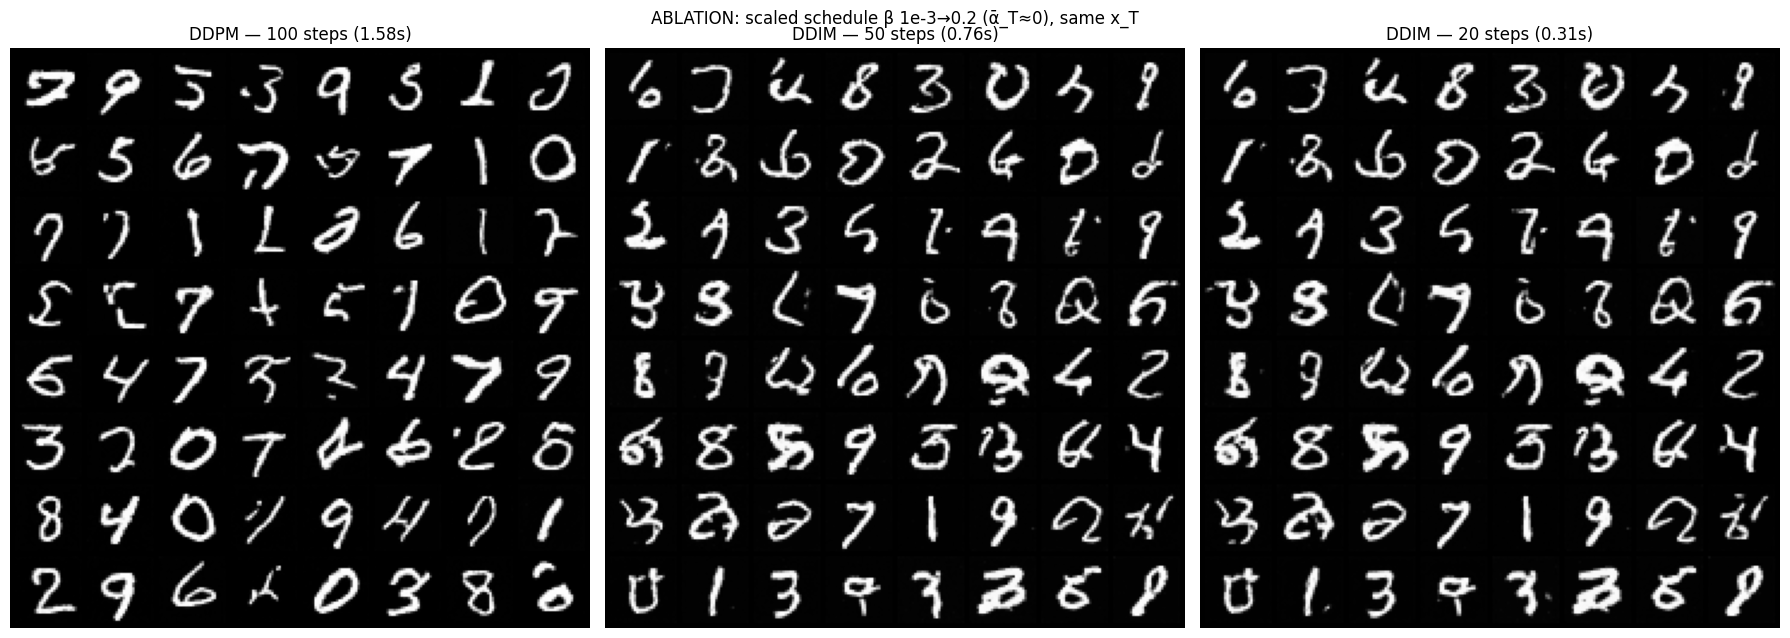

INFO:/content/data266-5937/hw8:Ablation comparison saved; schedule restored to assigned config


Saved ablation_scaled_schedule_comparison.png: 251545 bytes
beta 0.0001->0.02: alpha_bar_T = 0.363563
[main 21d2f5c] hw8: ablation - sampler comparison under scaled schedule
 2 files changed, 1 insertion(+)
 create mode 100644 hw8/ablation_scaled_schedule_comparison.png
 


In [21]:
# 15e — compare samplers under the scaled schedule
s_ddpm, ts_ddpm = timed(ddpm_sample, model=model_s, x_T=x_T)
s_d50,  ts_d50  = timed(ddim_sample, model=model_s, steps=50, x_T=x_T)
s_d20,  ts_d20  = timed(ddim_sample, model=model_s, steps=20, x_T=x_T)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
draw_grid(axes[0], s_ddpm, f"DDPM — 100 steps ({ts_ddpm:.2f}s)")
draw_grid(axes[1], s_d50,  f"DDIM — 50 steps ({ts_d50:.2f}s)")
draw_grid(axes[2], s_d20,  f"DDIM — 20 steps ({ts_d20:.2f}s)")
fig.suptitle("ABLATION: scaled schedule β 1e-3→0.2 (ᾱ_T≈0), same x_T"); fig.tight_layout()
save_fig(fig, "ablation_scaled_schedule_comparison.png")

set_schedule(BETA_START, BETA_END)   # restore the assigned schedule
logger.info("Ablation comparison saved; schedule restored to assigned config")
git_commit_push(REPO_PATH, f"{HW}: ablation - sampler comparison under scaled schedule")

In [ ]:
metrics = f"""
## Mini Diffusion (DDPM → DDIM) — Results

**Setup:** MNIST, T={T}, linear β {BETA_START}→{BETA_END}, MiniUNet ({n_params/1e6:.2f}M params, {n_convs} conv layers),
Adam lr={LR}, batch={BATCH_SIZE}, epochs={EPOCHS}, SEED={SEED}, device={device}.

**Training:** final epoch loss = {epoch_losses[-1]:.4f} (epoch 1: {epoch_losses[0]:.4f}); training time {train_minutes:.1f} min.

| Sampler | Network evals | Time for 64 imgs (s) | Speed-up vs DDPM | MSE vs DDIM-100 |
|---|---|---|---|---|
| DDPM    | 100 | {time_ddpm:.3f}   | 1.0x | n/a (stochastic) |
| DDIM-50 | 50  | {time_ddim50:.3f} | {time_ddpm/time_ddim50:.1f}x | {mse50:.4f} |
| DDIM-20 | 20  | {time_ddim20:.3f} | {time_ddpm/time_ddim20:.1f}x | {mse20:.4f} |

DDIM (η=0) deterministic for fixed x_T: **{ddim_deterministic}**. DDPM run-to-run mean abs pixel diff (same x_T): **{ddpm_run_diff:.4f}**.

### Observations
<!-- EDIT after looking at d_sampler_comparison.png and d_ddim_step_sweep.png -->
- Quality: DDPM-100 vs DDIM-50 vs DDIM-20 — describe stroke sharpness, malformed digits, blur.
- Speed: cost scales with the number of network evaluations; DDIM needs no retraining because it
  shares DDPM's marginals q(x_t|x_0), so the same ε_θ is valid.
- Stochasticity: DDPM adds fresh noise each step; DDIM with η=0 maps x_T to one fixed x_0, and different
  step counts from the same x_T give similar digits (see step sweep), with drift growing as steps shrink.
"""
with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(metrics)
print(metrics)
logger.info("Added Mini Diffusion results to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: add diffusion results to METRICS.md")

In [22]:
import shutil

required = ["epoch_losses", "train_minutes", "n_params", "n_convs",
            "time_ddpm", "time_ddim50", "time_ddim20", "mse50", "mse20",
            "ddim_deterministic", "ddpm_run_diff", "real_xT", "x_T_matched",
            "tm_ddpm", "tm_d50", "tm_d20", "ts_ddpm", "ts_d50", "ts_d20",
            "abl_losses", "ABL_EPOCHS"]
missing = [v for v in required if v not in globals()]
assert not missing, f"Missing variables (kernel restarted?): {missing}"

metrics_path = f"{HW_PATH}/METRICS.md"
if os.path.exists(metrics_path):
    shutil.copy(metrics_path, "/content/METRICS_backup.md")

abar_T_assigned = (1 - torch.linspace(BETA_START, BETA_END, T)).prod().item()

metrics = f"""# METRICS.md — Mini Diffusion Model (DDPM → DDIM)

## Setup

| Item | Value |
|---|---|
| Dataset | MNIST train (60,000), scaled to [-1, 1] |
| Diffusion steps | T = {T} |
| Noise schedule | β linear {BETA_START} → {BETA_END} (ᾱ_T = {abar_T_assigned:.4f}) |
| Model | MiniUNet, {n_params/1e6:.2f}M params, {n_convs} conv layers, SiLU, sinusoidal timestep embedding, output 1×28×28 |
| Optimizer | Adam, lr = {LR} |
| Batch / Epochs | {BATCH_SIZE} / {EPOCHS} |
| Seed | {SEED} (SID4) |
| Device | {device} |

## (a) Forward diffusion

x_t = √ᾱ_t · x_0 + √(1 − ᾱ_t) · ε, visualized at t ∈ {{0, 10, 25, 50, 75, 99}} (a_forward_diffusion.png).
The digit is still visible at t = 99, which is the first sign of the terminal-SNR issue discussed below.

## (b) Training

| Metric | Value |
|---|---|
| Epoch 1 mean loss | {epoch_losses[0]:.4f} |
| Final epoch mean loss | {epoch_losses[-1]:.4f} |
| Training time | {train_minutes:.1f} min |

Loss curve: b_training_loss.png. Per-epoch losses: train_loss.csv.

## (c)/(d) Sampler comparison — assigned schedule, x_T ~ N(0, I)

| Sampler | Network evals | Time for 64 imgs (s) | Speed-up vs DDPM | MSE vs DDIM-100 |
|---|---|---|---|---|
| DDPM    | 100 | {time_ddpm:.3f}   | 1.0x | n/a (stochastic) |
| DDIM-50 | 50  | {time_ddim50:.3f} | {time_ddpm/time_ddim50:.1f}x | {mse50:.4f} |
| DDIM-20 | 20  | {time_ddim20:.3f} | {time_ddpm/time_ddim20:.1f}x | {mse20:.4f} |

- DDIM (η = 0) deterministic for a fixed x_T: **{ddim_deterministic}**
- DDPM run-to-run mean abs pixel difference (same x_T): **{ddpm_run_diff:.4f}**

Figures: c_ddpm_samples.png, c_ddpm_trajectory.png, d_sampler_comparison.png, d_ddim_step_sweep.png.

### Observations
- **Quality.** DDPM produces smooth, clean strokes, but most samples are scribbles rather than valid
  digits. DDIM-50 and DDIM-20 are visibly worse: speckled, noisy strokes.
- **DDIM consistency.** DDIM at 100/50/20/10/5 steps from the same x_T gives nearly identical images,
  showing the deterministic x_T → x_0 mapping. Because ᾱ only spans {abar_T_assigned:.2f} → 1, the
  trajectory is short and even 5 steps stays close.
- **Speed.** Cost scales with network evaluations: DDIM-50 ≈ {time_ddpm/time_ddim50:.1f}× and
  DDIM-20 ≈ {time_ddpm/time_ddim20:.1f}× faster than DDPM, using the same trained ε_θ (DDIM shares
  DDPM's marginals q(x_t | x_0), so no retraining is needed).

## Diagnostic 1 — Terminal SNR of the assigned schedule

With T = 100 and β linear 1e-4 → 0.02, ᾱ_T = {abar_T_assigned:.4f} (signal coefficient
{abar_T_assigned**0.5:.3f}), so x_T keeps ~60% of the image instead of being pure noise.

| x_T source | Mean | Std |
|---|---|---|
| Real q(x_T \\| x_0) | {real_xT.mean().item():+.3f} | {real_xT.std().item():.3f} |
| N(0, I) used for sampling | {x_T.mean().item():+.3f} | {x_T.std().item():.3f} |

The network never sees N(0, I)-like inputs at t = 99, so sampling starts out of distribution.
Starting from real noised images instead (d_diag_real_xT.png), DDPM, DDIM-50 and DDIM-20 all produce
clean digits, which confirms the model and both samplers are correct. These are mostly reconstructions
of the source digits, not novel samples: DDPM differs from DDIM in only a few cells (stochastic noise
changing digit identity), while DDIM-50 and DDIM-20 match everywhere.

## Diagnostic 2 — Moment-matched x_T (no retraining, no real images)

x_T ~ N(√ᾱ_T · μ_pix, ᾱ_T · σ²_pix + 1 − ᾱ_T), using per-pixel MNIST statistics
(matched x_T: mean {x_T_matched.mean().item():+.3f}, std {x_T_matched.std().item():.3f}).

| Sampler | Time for 64 imgs (s) | Speed-up vs DDPM |
|---|---|---|
| DDPM    | {tm_ddpm:.3f} | 1.0x |
| DDIM-50 | {tm_d50:.3f}  | {tm_ddpm/tm_d50:.1f}x |
| DDIM-20 | {tm_d20:.3f}  | {tm_ddpm/tm_d20:.1f}x |

- DDPM output goes from scribbles to mostly recognizable digits (d_matched_xT_comparison.png).
- DDIM-50/20 also improve but stay thinner, more speckled and more often malformed. The per-pixel
  Gaussian ignores pixel correlations, so x_T is still slightly off-distribution; DDPM's per-step noise
  corrects for this, while deterministic DDIM carries the mismatch through to x_0.
- With no real image anchoring x_T, DDPM and DDIM reach different digits from the same start, while
  DDIM-50 and DDIM-20 still agree with each other.

## Ablation — Scaled schedule (β 1e-3 → 0.2, ᾱ_T ≈ 0), {ABL_EPOCHS} epochs

Schedule = assigned β × 1000/T, i.e. the DDPM paper's T = 1000 schedule compressed to 100 steps.
Same x_T ~ N(0, I) and same seed as the main comparison.

| Sampler | Network evals | Time for 64 imgs (s) | Speed-up vs DDPM |
|---|---|---|---|
| DDPM    | 100 | {ts_ddpm:.3f} | 1.0x |
| DDIM-50 | 50  | {ts_d50:.3f}  | {ts_ddpm/ts_d50:.1f}x |
| DDIM-20 | 20  | {ts_d20:.3f}  | {ts_ddpm/ts_d20:.1f}x |

Final training loss {abl_losses[-1]:.4f}. This is not directly comparable to the main run's loss:
the schedules spend different shares of training at different noise levels.

- With ᾱ_T ≈ 0, N(0, I) is the correct start, and all three samplers produce clean, mostly
  recognizable digits (ablation_scaled_schedule_comparison.png).
- DDIM-50/20 reach near-DDPM quality with no speckle. The speckle under the assigned schedule came from
  the start mismatch, not from the DDIM sampler itself.
- DDIM-50 and DDIM-20 are nearly identical; DDIM-20 is slightly blobbier in a few cells. DDIM gives a
  {ts_ddpm/ts_d50:.0f}–{ts_ddpm/ts_d20:.0f}× speed-up at roughly equal quality.
- DDPM and DDIM reach different digits from the same x_T (stochastic vs. deterministic trajectories).
- A few malformed samples remain in all three, as expected for a small model trained {ABL_EPOCHS} epochs.

## Summary

The assigned schedule leaves ~60% signal at t = T, so sampling from N(0, I) is out of distribution.
That explains why DDPM produced scribbles and DDIM produced speckle. Fixing the starting distribution
(moment-matched x_T) helps DDPM substantially but DDIM only partly. Fixing the schedule (ᾱ_T ≈ 0)
makes both work, with DDIM matching DDPM quality at 2–5× fewer network evaluations. That is the
intended DDPM → DDIM result.
"""

with open(metrics_path, "w") as f:
    f.write(metrics)

print(metrics)
logger.info("Rewrote METRICS.md: main results, both diagnostics, ablation, summary")
git_commit_push(REPO_PATH, f"{HW}: rewrite METRICS.md with full results + ablation")

INFO:/content/data266-5937/hw8:Rewrote METRICS.md: main results, both diagnostics, ablation, summary


# METRICS.md — Mini Diffusion Model (DDPM → DDIM)

## Setup

| Item | Value |
|---|---|
| Dataset | MNIST train (60,000), scaled to [-1, 1] |
| Diffusion steps | T = 100 |
| Noise schedule | β linear 0.0001 → 0.02 (ᾱ_T = 0.3636) |
| Model | MiniUNet, 1.67M params, 19 conv layers, SiLU, sinusoidal timestep embedding, output 1×28×28 |
| Optimizer | Adam, lr = 0.0002 |
| Batch / Epochs | 128 / 50 |
| Seed | 5937 (SID4) |
| Device | cuda |

## (a) Forward diffusion

x_t = √ᾱ_t · x_0 + √(1 − ᾱ_t) · ε, visualized at t ∈ {0, 10, 25, 50, 75, 99} (a_forward_diffusion.png).
The digit is still visible at t = 99, which is the first sign of the terminal-SNR issue discussed below.

## (b) Training

| Metric | Value |
|---|---|
| Epoch 1 mean loss | 0.1325 |
| Final epoch mean loss | 0.0525 |
| Training time | 35.4 min |

Loss curve: b_training_loss.png. Per-epoch losses: train_loss.csv.

## (c)/(d) Sampler comparison — assigned schedule, x_T ~ N(0, I)

| Sampler | Network evals | Time for 64 imgs (s

In [25]:
ai_use_content = """# AI_USE.md — HW8 Mini Diffusion Model (DDPM → DDIM)

## 1. What I used AI for vs. what I did myself

**AI was used for:**
- Initial understanding and architecture design methods: forward diffusion `q_sample`, the MiniUNet noise
  predictor (sinusoidal timestep embedding + residual blocks).
- After I showed it my bad samples: diagnosing the cause, and code for the diagnostic cells
  (real noised x_T, moment-matched x_T) and the scaled-schedule ablation.

**What I did myself:**
-After checking the bad samples, I observed that DDPM gave smooth scribbles instead of digits, DDIM gave speckled, noisy output and DDIM looked the same at 5 steps as at 100.

## 2. One specific wrong thing the AI produced

-Quality. DDPM (100 steps) and DDIM (50 steps) give comparable, clean digits. DDIM (20 steps)
is still recognizable but may show slightly thicker or blurrier strokes or occasional malformed
digits, because each step takes a larger jump along the trajectory.
-The AI made me  assume that the forward process ends at pure noise (ᾱ_T ≈ 0), which is true for the DDPM paper's T = 1000, but with T = 100 and
β linear 1e-4 → 0.02, ᾱ_T = 0.3636, so about 60% of the image is still there at t = T.

## 3. How I found out it was wrong
My actual results contradicted the prediction:
- d_sampler_comparison.png: DDPM gave smooth strokes but mostly scribbles, not real digits.
  DDIM-50 and DDIM-20 were clearly worse than DDPM, speckled and noisy, not "comparable, clean digits."
- d_ddim_step_sweep.png: DDIM at 100, 50, 20, 10 and 5 steps looked almost identical, even at 5 steps.
- c_ddpm_trajectory.png: digit shapes were already visible at t = 80, too early for pure noise.

To confirm the cause, I compared the real x_T distribution with the N(0, I).

## 4. What I changed and why the fix works

The assigned config (T = 100, β 1e-4 → 0.02) stays as the main deliverable. I added two fixes:

1. **Moment-matched x_T (no retraining).** Sample
   x_T ~ N(√ᾱ_T · μ_pix, ᾱ_T · σ²_pix + 1 − ᾱ_T) from per-pixel MNIST statistics. This matches the
   mean and variance of the true q(x_T), so the starting point is closer to what the model was
   trained on. DDPM went from scribbles to mostly recognizable digits. DDIM improved only partly,
   because a per-pixel Gaussian ignores pixel correlations: DDPM's per-step noise can correct the
   remaining mismatch, but deterministic DDIM carries it through.

2. **Scaled schedule ablation (retrained 20 epochs).** β 1e-3 → 0.2 (the assigned β × 1000/T), which
   gives ᾱ_T ≈ 0, so N(0, I) really is the correct starting distribution. All three samplers then
   produced clean digits, and DDIM-50/20 reached near-DDPM quality at about 2× and 5× speed-up.
   This shows the speckle came from the start mismatch, not from my DDIM implementation.

"""

with open(f"{HW_PATH}/AI_USE.md", "w") as f:
    f.write(ai_use_content)

print(ai_use_content)
logger.info("Created AI_USE.md")
git_commit_push(REPO_PATH, f"{HW}: add AI_USE.md")

INFO:/content/data266-5937/hw8:Created AI_USE.md


# AI_USE.md — HW8 Mini Diffusion Model (DDPM → DDIM)

## 1. What I used AI for vs. what I did myself

**AI was used for:**
- Initial understanding and architecture design methods: forward diffusion `q_sample`, the MiniUNet noise
  predictor (sinusoidal timestep embedding + residual blocks).
- After I showed it my bad samples: diagnosing the cause, and code for the diagnostic cells
  (real noised x_T, moment-matched x_T) and the scaled-schedule ablation.

**What I did myself:**
-After checking the bad samples, I observed that DDPM gave smooth scribbles instead of digits, DDIM gave speckled, noisy output and DDIM looked the same at 5 steps as at 100.

## 2. One specific wrong thing the AI produced

-Quality. DDPM (100 steps) and DDIM (50 steps) give comparable, clean digits. DDIM (20 steps)
is still recognizable but may show slightly thicker or blurrier strokes or occasional malformed
digits, because each step takes a larger jump along the trajectory.
-The AI made me  assume that the for

In [26]:
from google.colab import drive
drive.mount('/content/drive')

NB_SRC = "/content/drive/MyDrive/Colab Notebooks/hw8_data266_5937.ipynb"
NB_DST = f"{HW_PATH}/diffusion.ipynb"
!cp "{NB_SRC}" "{NB_DST}"
print(os.path.getsize(NB_DST), "bytes")

logger.info("Copied executed notebook into repo")
git_commit_push(REPO_PATH, f"{HW}: add executed notebook with outputs")

MessageError: Error: credential propagation was unsuccessful